# Interpretation · 單一預測、整個機群

**模型實際說了什麼**：給一台機台、一個時間點，接下來 72 小時內會不會出事、是哪一種；這些預測怎麼隨新資料更新；20 台機台在 test 期間會看到什麼。

| 節 | 問題 |
|---|---|
| 1 | 預警範圍用 72 小時合理嗎？預測範圍越長越不準嗎？ |
| 2 | 單一預測時間點，模型的輸出怎麼讀？ |
| 3 | 20 台機台、整個 test 期間，部署時會看到什麼？ |
| 4 | 全部預測時間點：四種實際結果下，模型平均說了什麼？ |


**解讀單位**

| 層級 | 例子 | 角色 |
|---|---|---|
| 機台 | 09M01 | 個體；跨 episode 的資訊靠事故歷史特徵（前一次類型、過去 30 天次數）帶進來 |
| episode | 09M01_100 | 從恢復生產到下一次事故，一段「處在風險中」的期間；每次事故後 `elapsed_h` 歸零 |
| 預測時間點 | (09M01_100, t) | **真正的預測單位**，每 5 分鐘一個 |

每個預測都是條件機率：**在這個 episode 撐到 t 還沒出事、已知 t 以前所有資料的前提下，接下來 72 小時內發生第 k 種故障的機率** P(T ≤ t + 72h, K = k | T > t, t 以前的資料)。

In [1]:
import os
from datetime import datetime
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import torch
import torch.nn as nn
from pycox.evaluation import EvalSurv
from lifelines import AalenJohansenFitter
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", message="The given NumPy array is not writable")
pd.set_option("display.width", 200)

BASE_DIR = os.path.abspath("..")
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
MODEL_RUN = "20261011_145955"                     # 讀這次 training 的模型權重與設定
MODEL_DIR = os.path.join(BASE_DIR, "results", MODEL_RUN)
# 結果存在該次 training 資料夾底下的 interpretation/；已經存在就另存 interpretation_<日期時間>/，不覆蓋之前的結果
OUT_DIR = os.path.join(MODEL_DIR, "interpretation")
if os.path.exists(OUT_DIR):
    OUT_DIR += "_" + datetime.now().strftime("%Y%m%d_%H%M%S")
os.makedirs(OUT_DIR, exist_ok=False)
print("模型：", MODEL_DIR)
print("結果會存在：", OUT_DIR)

模型： results/20261011_145955
結果會存在： results/20261011_145955/interpretation


In [2]:
# ----- training 的設定（從 hparams.json 讀）-----
HP = json.load(open(os.path.join(MODEL_DIR, "hparams.json")))
CAUSES = {int(k): v for k, v in HP["CAUSES"].items()}
NAMES = list(CAUSES.values())
FAULT_COLORS = HP["FAULT_COLORS"]
SEQ_COLS, STATIC_COLS = HP["SEQ_COLS"], HP["STATIC_COLS"]
CLIP, HORIZON_H, NUM_DURATIONS = HP["CLIP"], HP["HORIZON_H"], HP["NUM_DURATIONS"]
EDGES_H = np.array([0, 0.5, 1, 2, 4, 6, 9, 12, 18, 24, 36, 48, 72, 96, 120, 144, 168])   # 跟 02、training 一樣
assert len(EDGES_H) - 1 == NUM_DURATIONS
L = 64                                            # 用 L = 64 的模型

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

# ----- 這本的設定 -----
H = 72                                            # 預警範圍（小時）
B72 = int(np.searchsorted(EDGES_H, H)) - 1        # 「72 小時內」= 第 B72 格結束為止
B24 = int(np.searchsorted(EDGES_H, 24)) - 1
TAUS = [6, 24, 48, 72, 168]                       # 第 1 節比較的預測範圍
SEED_PICK = 314                                   # 第 2 節隨機挑例子

## 0. 重建前處理與模型

以下跟 training 第 1～5 節相同：讀資料、只用 train 標準化、組成 t 以前的序列、Dynamic-DeepHit 的結構、評估指標。模型只需要預測，所以拿掉了訓練用的 loss；RNN 預測用的層還是要定義，權重才載得進來。

In [3]:
windows = pd.read_parquet(os.path.join(PROCESSED_DIR, "windows.parquet"))
lm = pd.read_parquet(os.path.join(PROCESSED_DIR, "landmarks.parquet"))
ep = pd.read_parquet(os.path.join(PROCESSED_DIR, "episodes.parquet"))
lm = lm.merge(ep[["episode_id", "event"]].rename(columns={"event": "ep_event"}), on="episode_id")
C_VAL = lm.loc[lm.split == "train", "t"].max()
assert SEQ_COLS == [c for c in windows.columns if c not in ["tool", "episode_id", "win", "win_idx", "t_first", "t_last"]]

lm_tr = lm[(lm.split == "train") & lm["sample"]].reset_index(drop=True)
lm_va = lm[(lm.split == "val") & lm["sample"]].reset_index(drop=True)
lm_te = lm[(lm.split == "test") & lm["sample"]].reset_index(drop=True)
test_all = lm[(lm.split == "test") & lm.usable]                       # test 期間所有的窗（不只抽樣的 8%）
C_TEST = test_all.t.min()
print("train / val / test（抽樣）：", len(lm_tr), len(lm_va), len(lm_te), "；test 全部的窗：", len(test_all))

# sensor 特徵：只用 train 的窗標準化
seq = windows[SEQ_COLS].astype(float).copy()
for c in ["n_rows", "n_runs", "gap_s"]:
    seq[c] = np.log1p(seq[c])
is_train_win = (windows.t_last <= C_VAL).to_numpy()
seq_mean, seq_std = seq[is_train_win].mean(), seq[is_train_win].std().replace(0, 1)
SEQ = ((seq - seq_mean) / seq_std).clip(-CLIP, CLIP).to_numpy(np.float32)
first_row = pd.Series(np.arange(len(windows))).groupby(windows.episode_id.to_numpy()).min()

# 事故歷史：只用 train 的預測時間點標準化；每個窗用該窗當時的值
def static_features(d):
    f = pd.DataFrame(index=d.index)
    for p in ["none", "low", "high", "leak"]:
        f[f"prev_{p}"] = (d.prev_type == p).astype(float)
    for c in ["elapsed_h", "inc_7d", "inc_30d", "inc_30d_low", "inc_30d_high", "inc_30d_leak"]:
        f[c] = np.log1p(d[c].astype(float))
    return f

st_train = static_features(lm[lm.split == "train"])
st_mean, st_std = st_train.mean(), st_train.std().replace(0, 1)
assert list(st_train.columns) == STATIC_COLS
key_cols = ["episode_id", "win_idx"]
history_rows = lm[key_cols + ["t", "prev_type", "elapsed_h", "inc_7d", "inc_30d", "inc_30d_low", "inc_30d_high", "inc_30d_leak"]].drop_duplicates(key_cols)
window_history = windows[key_cols].merge(history_rows, on=key_cols, how="left", validate="one_to_one", sort=False)
HISTORY_SEQ = ((static_features(window_history) - st_mean) / st_std).clip(-CLIP, CLIP).to_numpy(np.float32)

def make_batch(d, L=L):
    # 每個預測時間點：t 以前（含）最近的 L 個窗（sensor + 各窗當時的事故歷史），不足 L 個的後面補 0
    end = first_row.loc[d.episode_id].to_numpy() + d.win_idx.to_numpy()
    lengths = np.minimum(d.win_idx.to_numpy() + 1, L)
    rows = (end - lengths + 1)[:, None] + np.arange(L)[None, :]
    valid = np.arange(L)[None, :] < lengths[:, None]
    idx = np.where(valid, rows, 0)
    x = np.concatenate([SEQ[idx], HISTORY_SEQ[idx]], axis=2) * valid[..., None]
    return x.astype(np.float32), lengths.astype(np.int64)

train / val / test（抽樣）： 61460 15385 26252 ；test 全部的窗： 329906


In [4]:
class DynamicDeepHit(nn.Module):
    # 跟 training 第 4 節一樣（只保留預測會用到的 forward）
    def __init__(self, x_dim, h_rnn, h_fc, dropout, n_rnn):
        super().__init__()
        n_ev = len(CAUSES)
        self.drop = nn.Dropout(dropout)
        RNN = nn.LSTM if HP["DDH_RNN_TYPE"] == "LSTM" else nn.GRU
        self.rnns = nn.ModuleList([RNN(x_dim if i == 0 else h_rnn, h_rnn, batch_first=True) for i in range(n_rnn)])
        self.att = nn.Sequential(nn.Linear(n_rnn * h_rnn + x_dim, h_fc), nn.Tanh(), self.drop, nn.Linear(h_fc, 1))
        self.z_mean = nn.Linear(h_rnn, x_dim)                                 # RNN 預測 loss 用；預測時不用，但權重要載得進來
        self.z_std = nn.Linear(h_rnn, x_dim)
        self.shared = nn.Linear(x_dim + n_rnn * h_rnn, h_fc)
        self.cs = nn.ModuleList([
            nn.Sequential(nn.Linear(h_fc, h_fc), nn.ReLU(), self.drop, nn.Linear(h_fc, h_fc), nn.ReLU())
            for _ in range(n_ev)
        ])
        self.out = nn.Linear(n_ev * h_fc, n_ev * NUM_DURATIONS + 1)
        self.ctx_dim = n_rnn * h_rnn

    def forward(self, x, lengths):
        B, L, _ = x.shape
        lengths = lengths.long()
        x_last = x[torch.arange(B, device=x.device), lengths - 1]
        if L == 1:
            context = x.new_zeros(B, self.ctx_dim)
        else:
            hist_mask = (torch.arange(L - 1, device=x.device)[None, :] < (lengths - 1)[:, None]).float()
            inp = x[:, :-1] * hist_mask[..., None]
            states = []
            for rnn in self.rnns:
                h, _ = rnn(self.drop(inp))
                states.append(h)
                inp = self.drop(h)
            h_all = torch.cat(states, dim=-1)
            e = self.att(torch.cat([h_all, x_last[:, None, :].expand(-1, L - 1, -1)], dim=-1)).squeeze(-1)
            a = torch.softmax(e.masked_fill(hist_mask == 0, -1e9), dim=1) * hist_mask
            context = (a[..., None] * h_all).sum(1)
        hdn = self.drop(torch.relu(self.shared(torch.cat([x_last, context], dim=1))))
        out = self.drop(torch.cat([cs(hdn) for cs in self.cs], dim=1))
        prob = torch.softmax(self.out(out), dim=1)
        return prob[:, :-1].view(B, len(CAUSES), NUM_DURATIONS)


net = DynamicDeepHit(len(SEQ_COLS) + len(STATIC_COLS), HP["DDH_H_RNN"], HP["DDH_H_FC"], HP["DDH_DROPOUT"],
                     HP["DDH_LAYERS_RNN"]).to(DEVICE)
net.load_state_dict(torch.load(os.path.join(MODEL_DIR, f"ddh_L{L}.pt"), map_location=DEVICE))
net.eval()

@torch.no_grad()
def predict_cif(d, chunk=20000, batch_size=2048):
    # 完整 CIF，shape (3, 16, N)：第 k 種故障在每個時間格結束前發生的機率（從 t 起算）
    out = []
    for s in range(0, len(d), chunk):                                       # 分段組序列，避免一次占太多記憶體
        xs, lengths = make_batch(d.iloc[s:s + chunk])
        for i in range(0, len(lengths), batch_size):
            pmf = net(torch.from_numpy(xs[i:i + batch_size]).to(DEVICE), torch.from_numpy(lengths[i:i + batch_size]).to(DEVICE))
            out.append(pmf.cumsum(2).cpu().numpy())
    return np.concatenate(out).transpose(1, 2, 0)

In [5]:
# 評估（跟 training 第 5 節一樣）
def aj_cif(d):
    dur = np.minimum(d.residual_h.to_numpy(), HORIZON_H)
    ev = np.where(d.residual_h.to_numpy() > HORIZON_H, 0, d.event.to_numpy())
    out = np.zeros((len(CAUSES), NUM_DURATIONS))
    for k in CAUSES:
        ajf = AalenJohansenFitter(calculate_variance=False, seed=0)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ajf.fit(dur, ev, event_of_interest=k)
        cd = ajf.cumulative_density_.iloc[:, 0]
        out[k - 1] = [cd[cd.index <= t].iloc[-1] for t in EDGES_H[1:]]
    return out

def censor_km(time_idx, event):
    G = np.ones(NUM_DURATIONS + 1)
    for m in range(NUM_DURATIONS):
        cens = ((event == 0) & (time_idx == m)).sum()
        at_risk = (time_idx > m).sum() + cens
        G[m + 1] = G[m] * (1 - cens / at_risk) if at_risk else G[m]
    return G

def ipcw_brier(p, time_idx, event, cause, b, G):
    happened = (event > 0) & (time_idx <= b)
    survived = ((event > 0) & (time_idx > b)) | ((event == 0) & (time_idx >= b))
    w = np.zeros(len(event))
    w[happened] = 1 / G[time_idx[happened]]
    w[survived] = 1 / G[b]
    y = (happened & (event == cause)).astype(float)
    return np.mean(w * (y - p) ** 2)

def evaluate(cif, d):
    t, e = d.time_idx.to_numpy(), d.event.to_numpy()
    G = censor_km(t, e)
    rows = []
    for k, cause in CAUSES.items():
        surv = pd.DataFrame(1 - cif[k - 1], index=np.arange(NUM_DURATIONS))
        bs = ipcw_brier(cif[k - 1, B24], t, e, k, B24, G)
        bs_null = ipcw_brier(np.full(len(d), NULL_CIF[k - 1, B24]), t, e, k, B24, G)
        rows.append({"cause": cause, "c_index": EvalSurv(surv, t, (e == k).astype(int)).concordance_td(),
                     "ipa_24h": 1 - bs / bs_null})
    return pd.DataFrame(rows)

NULL_CIF = aj_cif(lm_tr)                          # 不看任何特徵的平均風險（train）

# 檢查：讀回來的模型，test 指標要跟那次 training 的 metrics.csv 一樣
cif_va, cif_te = predict_cif(lm_va), predict_cif(lm_te)
check = evaluate(cif_te, lm_te)
ref = pd.read_csv(os.path.join(MODEL_DIR, "metrics.csv"))
ref = ref[ref.model == f"Dynamic-DeepHit L={L}"].set_index("cause").loc[NAMES]
assert np.allclose(check[["c_index", "ipa_24h"]].to_numpy(), ref[["c_index", "ipa_24h"]].to_numpy(), atol=1e-3), "跟 training 的結果不一致"
print("模型與前處理重建檢查通過")
check.round(3)

模型與前處理重建檢查通過


,cause,c_index,ipa_24h
0,low,0.815,0.245
1,high,0.835,0.031
2,leak,0.667,0.024


## 1. 預警範圍：預測範圍越長，越不準嗎？

模型輸出的是 0～168 小時的完整累積發生率（CIF），可以讀任何一個時間格，**不用重新訓練**。選 72 小時是假設給 3 天準備維修。

在 τ = 6、24、48、72、168 小時：

- **AUC**（time-dependent）：τ 以前發生這種故障的時間點，預測機率是否比其他時間點高；對照組 = τ 以前沒發生這種故障的所有時間點（含其他故障）。τ 以前就被資料結尾截尾的時間點結果未知，不算。
- **IPA@τ**：相對於 train 平均風險的進步（跟 training 第 5 節一樣）。
- **實際／預測**：τ 以內實際出事的比例，和模型平均預測的機率。

In [6]:
def by_horizon(cif, d):
    rh, ev, t_idx = d.residual_h.to_numpy(), d.event.to_numpy(), d.time_idx.to_numpy()
    G = censor_km(t_idx, ev)
    rows = []
    for tau in TAUS:
        b = int(np.searchsorted(EDGES_H, tau)) - 1
        known = ~((ev == 0) & (rh <= tau))                # τ 以前就截尾 → 結果未知
        hit_any = (ev > 0) & (rh <= tau)
        p_any = cif[:, b].sum(0)
        r = {"tau_h": tau, "observed": hit_any[known].mean(), "predicted": p_any[known].mean(),
             "auc_any": roc_auc_score(hit_any[known], p_any[known])}
        for k, c in CAUSES.items():
            r[f"auc_{c}"] = roc_auc_score((hit_any & (ev == k))[known], cif[k - 1, b][known])
        for k, c in CAUSES.items():
            bs = ipcw_brier(cif[k - 1, b], t_idx, ev, k, b, G)
            bs_null = ipcw_brier(np.full(len(ev), NULL_CIF[k - 1, b]), t_idx, ev, k, b, G)
            r[f"ipa_{c}"] = 1 - bs / bs_null
        rows.append(r)
    return pd.DataFrame(rows)

horizon = pd.concat({"val": by_horizon(cif_va, lm_va), "test": by_horizon(cif_te, lm_te)}, names=["split", None])
horizon = horizon.reset_index(level=1, drop=True).set_index("tau_h", append=True)
horizon.to_csv(os.path.join(OUT_DIR, "by_horizon.csv"))
horizon.round(3)

observed  predicted  auc_any  auc_low  auc_high  auc_leak  ipa_low  ipa_high  ipa_leak
split tau_h                                                                                        
val   6         0.028      0.028    0.849    0.879     0.700     0.755    0.100    -0.006    -0.007
      24        0.078      0.085    0.852    0.888     0.726     0.656    0.261     0.002    -0.012
      48        0.133      0.143    0.829    0.879     0.714     0.615    0.339     0.009    -0.011
      72        0.174      0.188    0.813    0.865     0.714     0.587    0.357     0.011    -0.008
      168       0.294      0.324    0.765    0.801     0.736     0.570    0.282     0.034    -0.002
test  6         0.024      0.027    0.856    0.906     0.795     0.839    0.099     0.008     0.017
      24        0.070      0.082    0.841    0.896     0.834     0.747    0.245     0.031     0.024
      48        0.119      0.138    0.818    0.876     0.858     0.678    0.284     0.064     0.018
      72        0.160      0.182    0.801    0.853     0.883     0.624    0.264     0.116     0.013
      168       0.279      0.314    0.787    0.826     0.867     0.647    0.237     0.189     0.015

**看到**

- **排序：整體越長越差，但要看故障類型。** 任何故障的 AUC：val 0.849 → 0.765、test 0.856 → 0.787（6 → 168 小時）。壓力過低和洩漏也是越長越差，洩漏最明顯（只有短期內分得出來）；壓力過高在 test 上反而越長越好。
- **機率準確度沒有越長越差。** 壓力過低的 IPA 在 48～72 小時最好（val 0.357、test 0.264）。短範圍的 IPA 偏低，是因為 6 小時內出事太少見，連平均風險都不容易贏過。
- **72 小時是合理的預警範圍**：任何故障的 AUC 約 0.80～0.81（val／test），壓力過低的機率明顯比平均風險準。
- **壓力過高 72 小時的 IPA 在 test 上是 0.116，但 val 只有 0.011** → 這個進步在 val 上沒有重現，洩漏在任何範圍都沒有比平均風險準。
- 模型平均預測略高於實際發生率（72 小時：test 0.182 vs 0.160），略微高估。

## 2. 單一預測時間點怎麼讀

從 test 抽樣的預測時間點中，用 seed 314 **隨機挑一個**。模型在這個時間點的輸出分三層讀：

1. **72 小時內會不會出事**：P(任何故障 ≤ 72h) = 三種故障的 CIF 加總
2. **三種故障各自的機率**：P(壓力過低 ≤ 72h)、P(壓力過高 ≤ 72h)、P(洩漏 ≤ 72h)，都是絕對機率
3. （可選）**如果真的出事，比較可能是哪一種**：第 2 層 ÷ 第 1 層

第 3 層一定要跟第 1 層一起看：「如果出事，壓力過低 80%」聽起來很確定，但如果第 1 層只有 3%，意思是「模型覺得幾乎不會出事；那一點點機率裡，大部分給壓力過低」。

不報「預計 X 小時後故障」：大部分時間點的累積機率到 72 小時（甚至 168 小時）都不到 0.5，中位數不存在。

In [7]:
def three_layers(c3):
    # 單一時間點的三層讀法；c3: (3, 16)
    p = c3[:, B72]
    return {"any_24h": c3[:, B24].sum(), "any_72h": p.sum(),
            **{f"{c}_72h": p[i] for i, c in enumerate(NAMES)},
            **{f"if_fails_{c}": p[i] / p.sum() for i, c in enumerate(NAMES)}}

rng = np.random.default_rng(SEED_PICK)
one = lm_te.iloc[[rng.integers(len(lm_te))]]
c_one = cif_te[:, :, one.index[0]]
r = one.iloc[0]
if r.event > 0 and r.residual_h <= H:
    actual = f"{CAUSES[r.event]}，{r.residual_h:.1f} 小時後"
elif r.ep_event == "censored":
    actual = f"{H} 小時內沒出事；到資料結束（{(r.ep_end - r.t) / 3600:.0f} 小時後）都沒再出事"
else:
    actual = f"{H} 小時內沒出事；下一次是 {r.ep_event}，{(r.ep_end - r.t) / 3600:.0f} 小時後"
print(f"機台 {r.tool}，episode {r.episode_id}：恢復生產後 {r.elapsed_h:.0f} 小時，前一次事故 {r.prev_type}，過去 30 天 {r.inc_30d} 次")
print("實際：", actual)
pd.Series(three_layers(c_one)).round(3).to_frame("機率")

機台 05M02，episode 05M02_020：恢復生產後 188 小時，前一次事故 high，過去 30 天 2 次
實際： 72 小時內沒出事；到資料結束（797 小時後）都沒再出事


,機率
any_24h,0.034
any_72h,0.120
low_72h,0.036
high_72h,0.074
leak_72h,0.010
if_fails_low,0.300
if_fails_high,0.616
if_fails_leak,0.085


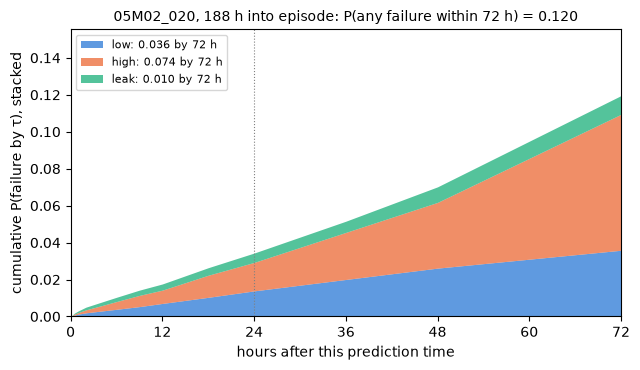

In [8]:
edges = EDGES_H[:B72 + 2]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
base = np.zeros(len(edges))
for i, c in enumerate(NAMES):                                     # 三種故障的 CIF 疊起來，總高度 = 任何故障
    top = base + np.r_[0, c_one[i, :B72 + 1]]
    ax.fill_between(edges, base, top, color=FAULT_COLORS[c], alpha=0.75, lw=0, label=f"{c}: {c_one[i, B72]:.3f} by 72 h")
    base = top
if r.event > 0 and r.residual_h <= H:
    ax.axvline(r.residual_h, color="black", lw=1.5)
ax.axvline(24, color="gray", ls=":", lw=0.8)
ax.set_xlim(0, H)
ax.set_xticks(range(0, H + 1, 12))
ax.set_ylim(0, max(0.1, base[-1] * 1.3))
ax.set_xlabel("hours after this prediction time")
ax.set_ylabel("cumulative P(failure by τ), stacked")
ax.set_title(f"{r.episode_id}, {r.elapsed_h:.0f} h into episode: P(any failure within 72 h) = {base[-1]:.3f}", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "one_prediction.png"), dpi=150)
plt.show()

title: 05M02，恢復生產後 188 小時，前一次事故是壓力過高，過去 30 天 2 次

| 層 | 模型說 |
|---|---|
| 1. 72 小時內會不會出事 | **0.12**（24 小時內 0.03），比 train 的平均 72 小時風險（0.17）低 |
| 2. 三種故障各自 | 壓力過高 0.074、壓力過低 0.036、洩漏 0.010 |
| 3. 如果出事，是哪一種 | 壓力過高 62%、壓力過低 30%、洩漏 8% |

實際：72 小時內沒出事，而且到資料結束（797 小時後）都沒再出事。

- 只看第 3 層會以為「模型 62% 確定是壓力過高」；其實模型覺得**幾乎不會出事**，只有 7% 的機率是壓力過高。所以第 3 層一定要跟第 1 層一起報。
- 壓力過高排第一，是因為前一次事故是壓力過高（事故歷史）。
- 累積曲線幾乎是一條直線：模型沒有說出「哪個時段特別危險」，只是把機率平均攤在 72 小時上。

## 3. 呈現 20 台機台的 72h risk trajectory

每個新的 5 分鐘窗進來，就更新每台機台「接下來 72 小時內出任何故障」的機率。

- x = test 期間的日曆時間；y = P(任何故障 ≤ 72h)。每 5 分鐘的預測跳動很大，這裡取**每小時平均**；沒有資料的小時（沒在加工、停機）留白。
- 豎線 = 實際故障，顏色 = 類型。虛線 = train 的平均 72 小時風險。
- 每個 episode 結束（故障）後，`elapsed_h` 歸零、事故歷史更新，所以曲線在故障後會重新開始，不是整台機台的一條 survival curve。

In [11]:
cif_all = predict_cif(test_all)
fleet = pd.DataFrame({"tool": test_all.tool.to_numpy(), "hour": ((test_all.t - C_TEST) // 3600).to_numpy().astype(int),
                      "p_any_72h": cif_all[:, B72].sum(0), **{f"{c}_72h": cif_all[i, B72] for i, c in enumerate(NAMES)}})
hourly = fleet.groupby(["tool", "hour"]).mean()
hourly.to_csv(os.path.join(OUT_DIR, "fleet_hourly_72h.csv"))

fails = ep[(ep.event != "censored") & (ep.end > C_TEST)]
fails = fails.assign(day=(fails.end - C_TEST) / 86400)
tools = sorted(test_all.tool.unique())
n_hours = fleet.hour.max() + 1
null_any = NULL_CIF[:, B72].sum()
print(len(tools), "台機台，test 期間", round(n_hours / 24), "天，", len(fails), "次故障")

20 台機台，test 期間 171 天， 262 次故障


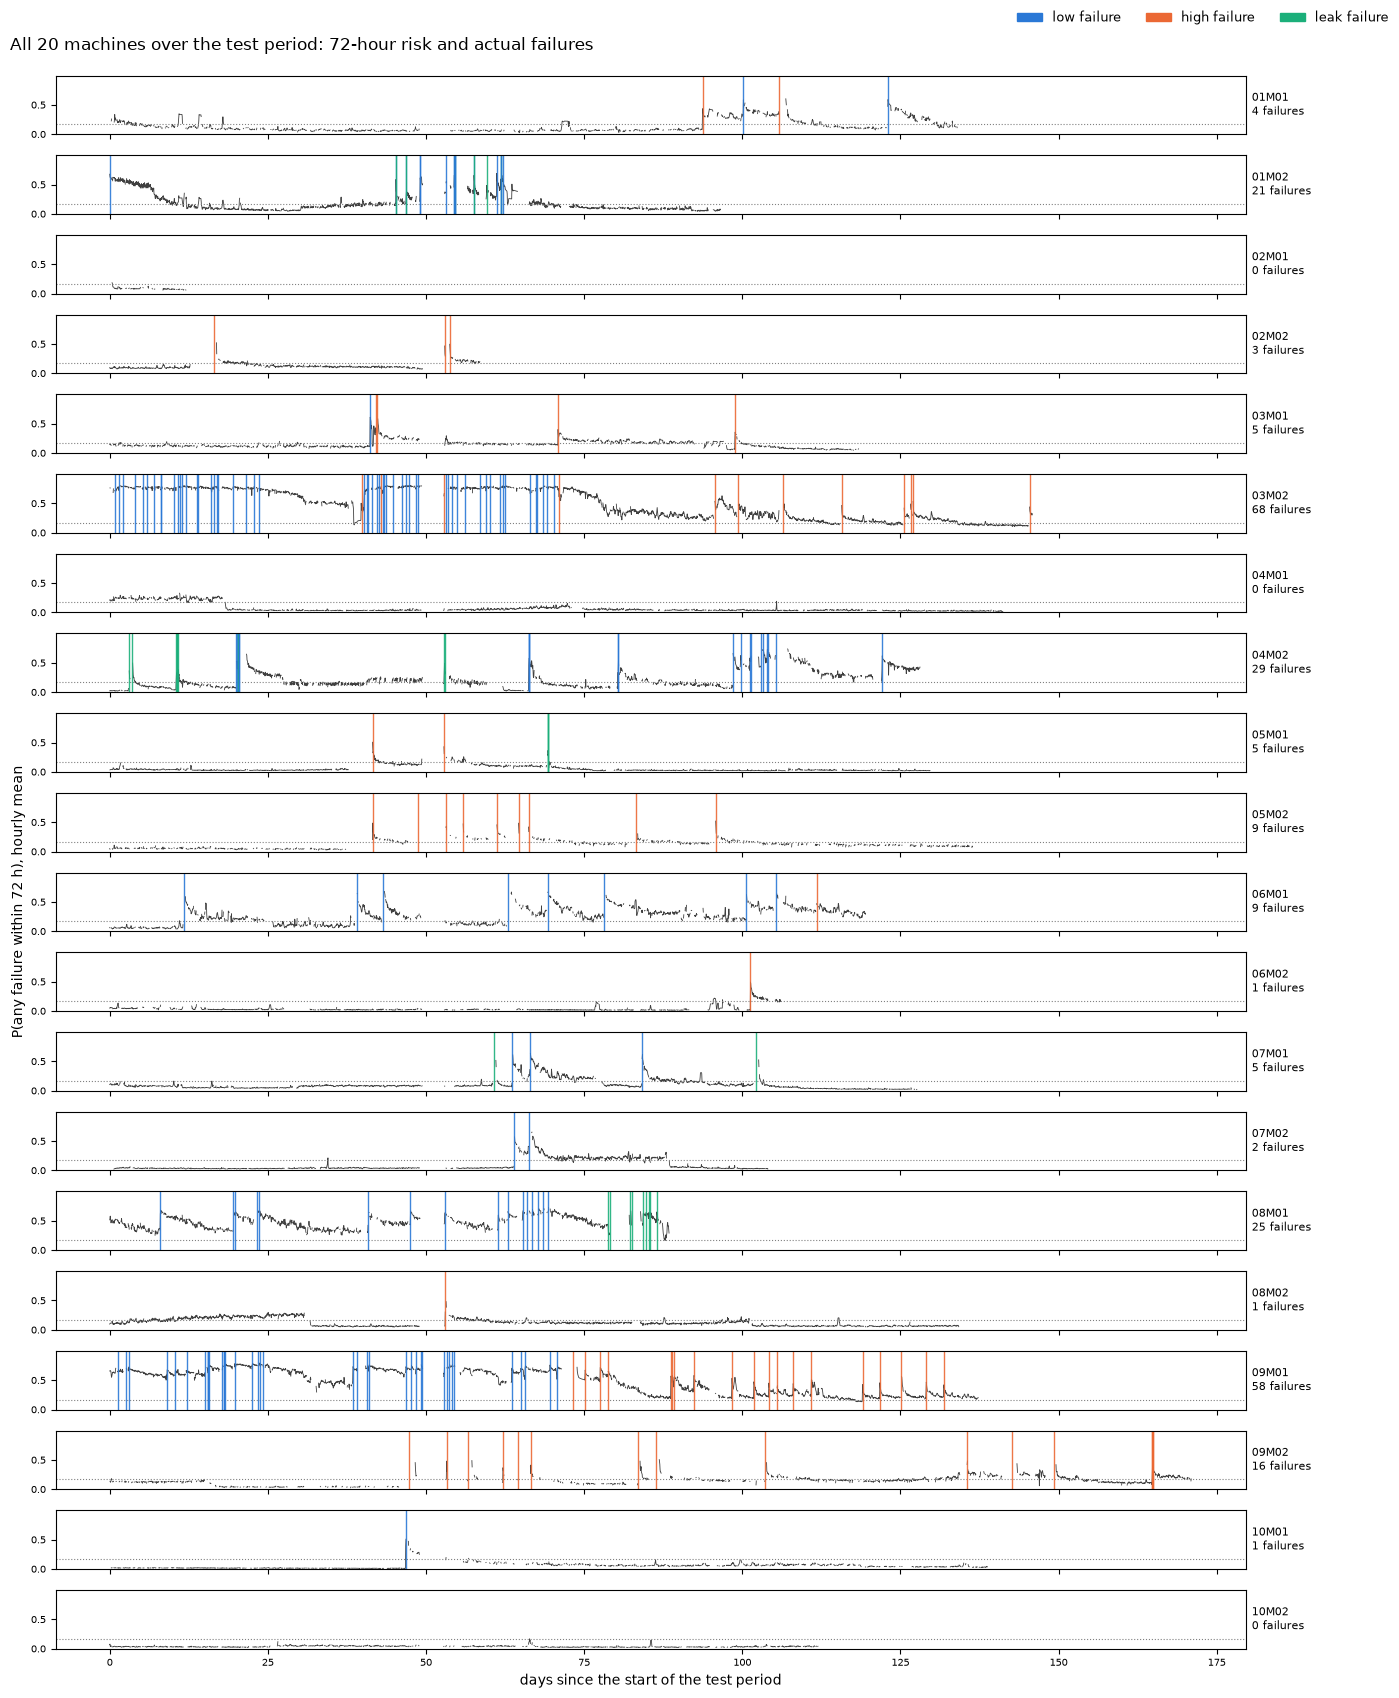

In [12]:
fig, axes = plt.subplots(len(tools), 1, figsize=(14, 0.85 * len(tools)), sharex=True, sharey=True)
for ax, tool in zip(axes, tools):
    s = hourly.loc[tool, "p_any_72h"].reindex(range(n_hours))               # 沒有資料的小時 → NaN，線會斷開
    ax.plot(np.arange(n_hours) / 24, s.to_numpy(), color="0.25", lw=0.6)
    ax.axhline(null_any, color="gray", ls=":", lw=0.8)
    f = fails[fails.tool == tool]
    for _, row in f.iterrows():
        ax.axvline(row.day, color=FAULT_COLORS[row.event], lw=1, alpha=0.9)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5])
    ax.tick_params(labelsize=7)
    ax.text(1.005, 0.5, f"{tool}\n{len(f)} failures", transform=ax.transAxes, va="center", fontsize=8)
axes[-1].set_xlabel("days since the start of the test period")
axes[len(tools) // 2].set_ylabel(f"P(any failure within {H} h), hourly mean")
fig.legend(handles=[Patch(color=FAULT_COLORS[c], label=f"{c} failure") for c in NAMES], loc="upper right", ncol=3, fontsize=9, frameon=False)
fig.suptitle(f"All 20 machines over the test period: {H}-hour risk and actual failures", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 0.95, 0.985))
fig.savefig(os.path.join(OUT_DIR, "fleet_72h.png"), dpi=150)
plt.show()

In [13]:
# 每台機台：test 期間的平均風險、故障次數
per_tool = hourly.groupby("tool").p_any_72h.agg(["mean", "max"]).add_prefix("p_any_72h_")
per_tool["failures"] = fails.groupby("tool").size().reindex(per_tool.index, fill_value=0)
per_tool["hours_with_data"] = hourly.groupby("tool").size()
print("機台的平均風險 vs 故障次數，Spearman：", round(spearmanr(per_tool.p_any_72h_mean, per_tool.failures).statistic, 2))
per_tool.sort_values("p_any_72h_mean", ascending=False).round(3)

機台的平均風險 vs 故障次數，Spearman： 0.86


,p_any_72h_mean,p_any_72h_max,failures,hours_with_data
tool,,,,
09M01,0.474,0.794,58,2548
03M02,0.468,0.812,68,2775
08M01,0.467,0.728,25,1397
06M01,0.252,0.679,9,1816
04M02,0.212,0.736,29,1865
01M02,0.191,0.689,21,1742
09M02,0.154,0.505,16,1710
03M01,0.150,0.611,5,1698
01M01,0.144,0.603,4,1694


圖上的模式是「故障後跳高、慢慢下降」。用數字確認：每次故障前 72 小時內（同一個 episode）的平均預測風險，依**同一台機台近 7 天有沒有出過事**分組。對照：離下一次故障還超過 72 小時的時間點。

In [14]:
test_ex = test_all.assign(hours_to_end=(test_all.ep_end - test_all.t) / 3600)   # 每個時間點離 episode 結束還有幾小時
test_ex["p_any_72h"] = cif_all[:, B72].sum(0)
pre = test_ex[(test_ex.ep_event != "censored") & (test_ex.hours_to_end <= H)]
per_fail = pre.groupby("episode_id").agg(p_any_72h=("p_any_72h", "mean"), inc_7d=("inc_7d", "last"))
per_fail["kind"] = np.where(per_fail.inc_7d > 0, "repeat (failure in previous 7 d)", "first (no failure in previous 7 d)")
quiet = test_ex.loc[test_ex.hours_to_end > H, "p_any_72h"]

def risk_summary(s):
    return pd.Series({"n": len(s), "median": s.median(), f"> train avg ({null_any:.2f})": (s > null_any).mean(), "> 0.3": (s > 0.3).mean()})

print(len(fails) - len(per_fail), "次故障前 72 小時內沒有任何預測時間點")
pd.concat({**{k: risk_summary(g.p_any_72h) for k, g in per_fail.groupby("kind")},
           "quiet (> 72 h before next failure)": risk_summary(quiet)}, axis=1).T.round(3)

6 次故障前 72 小時內沒有任何預測時間點


,n,median,> train avg (0.17),> 0.3
first (no failure in previous 7 d),48.0,0.128,0.292,0.167
repeat (failure in previous 7 d),208.0,0.629,0.971,0.851
quiet (> 72 h before next failure),270022.0,0.090,0.282,0.125


**看到**

- **鋸齒狀**：幾乎每次故障後，風險立刻跳高，之後慢慢下降，直到下一次故障。模型在回應「剛出過事」，而不是在故障前提早升高。
- **機台之間分得很開**：平均風險跟 test 期間的故障次數高度一致（Spearman 0.86）。09M01、03M02、08M01 平均約 0.47，test 期間各出事 25～68 次；04M01、10M02 等沒出事的機台平均 < 0.1。
- **能預警的主要是接連發生的故障**：
  - 同一台近 7 天有出過事的故障（208 次），故障前 72 小時的風險中位數 **0.63**，85% 高於 0.3。
  - 近 7 天沒出過事的故障（48 次），中位數只有 **0.13**，跟平靜時段（0.09）差不多，只有 17% 高於 0.3。
  - 平靜時段也有 12.5% 的時間點高於 0.3（多半是剛出過事、但之後沒有再壞的時段）。
- 6 次故障前 72 小時內沒有任何預測時間點（機台沒在加工），這些不管模型多好都無法預警。

→ 部署的話，它比較像「哪幾台機台這幾天正在密集出事、要盯緊」的提醒，而不是在近 7 天沒出過事的機台上提早發現問題。

## 4. 全部預測時間點：四種結果下，模型平均說了什麼

test 抽樣的全部預測時間點，依 72 小時內的實際結果分組（72 小時前就被資料結尾截尾的，結果未知，不算）。「哪一種」跟最簡單的規則比：**直接猜前一次事故的類型**（沒有前一次的猜壓力過低，也就是最常見的類型）。

In [15]:
def outcome_within(d, h=H):
    # h 小時內的實際結果：low / high / leak / none；h 小時前就截尾 → unknown
    out = np.where(d.residual_h > h, "none", "unknown").astype(object)
    hit = ((d.event > 0) & (d.residual_h <= h)).to_numpy()
    out[hit] = d.event[hit].map(CAUSES).to_numpy()
    return out

outcome_te = outcome_within(lm_te)
known = outcome_te != "unknown"
p72 = cif_te[:, B72][:, known]
agg = pd.DataFrame({"actual": outcome_te[known], "p_any_72h": p72.sum(0),
                    **{f"p_{c}_72h": p72[i] for i, c in enumerate(NAMES)},
                    "model_type": np.array(NAMES)[p72.argmax(0)],
                    "prev_type": lm_te.prev_type.to_numpy()[known]})
agg["prev_type"] = agg.prev_type.where(agg.prev_type != "none", "low")

by_outcome = agg.groupby("actual").agg(n=("p_any_72h", "size"), **{c: (c, "mean") for c in ["p_any_72h"] + [f"p_{c}_72h" for c in NAMES]})
by_outcome["model_type_correct"] = (agg.model_type == agg.actual).groupby(agg.actual).mean()
by_outcome["prev_type_correct"] = (agg.prev_type == agg.actual).groupby(agg.actual).mean()
by_outcome = by_outcome.loc[NAMES + ["none"]]
by_outcome.loc["none", ["model_type_correct", "prev_type_correct"]] = np.nan     # 沒出事就沒有「類型」
by_outcome.to_csv(os.path.join(OUT_DIR, "by_outcome_72h.csv"))

failed = agg[agg.actual != "none"]
print("72 小時內有出事的時間點，類型猜對：模型", round((failed.model_type == failed.actual).mean(), 3),
      "／ 猜前一次事故類型", round((failed.prev_type == failed.actual).mean(), 3))
by_outcome.round(3)

72 小時內有出事的時間點，類型猜對：模型 0.781 ／ 猜前一次事故類型 0.826


,n,p_any_72h,p_low_72h,p_high_72h,p_leak_72h,model_type_correct,prev_type_correct
actual,,,,,,,
low,2351,0.474,0.407,0.047,0.021,0.984,0.861
high,1350,0.264,0.135,0.111,0.019,0.659,0.857
leak,398,0.225,0.159,0.043,0.023,0.000,0.508
none,21491,0.144,0.094,0.038,0.012,NaN,NaN


**看到**

- **會不會出事：分得開。** 72 小時內真的出事的時間點，模型平均給 0.23～0.47；沒出事的平均 0.14。
- **三種故障各自的機率**：實際是壓力過低時，P(壓力過低) 平均 0.41；但實際是壓力過高時，P(壓力過高) 只有 0.11，還低於 P(壓力過低) 0.14；實際是洩漏時，P(洩漏) 只有 0.02。模型整體偏向壓力過低。
- **哪一種：沒有贏過「猜前一次事故類型」。** 模型整體猜對 78%，前一次類型 83%。壓力過低 98%，但壓力過高 66%、**洩漏 0%**（前一次類型還有 51%）。

## 結論

| 問題 | 回答 |
|---|---|
| 預警範圍 | 72 小時：任何故障的 AUC 約 0.80（val／test），壓力過低的機率明顯比平均風險準。排序能力隨預測範圍拉長而下降，機率準確度沒有 |
| 單一預測怎麼讀 | 三層：72 小時內出事的機率 → 三種故障各自的絕對機率 →（可選）如果出事是哪一種。不報「預計 X 小時後故障」，因為累積機率多半到不了 0.5 |
| 部署時會看到什麼 | 故障後跳高、慢慢下降的鋸齒；機台之間分得開（Spearman 0.86）。近 7 天有出過事的故障，故障前風險中位數 0.63；近 7 天沒出過事的只有 0.13 |
| 會不會出事、哪一種 | 會不會出事分得開（0.23～0.47 vs 0.14）；故障類型沒有贏過「猜前一次事故類型」（78% vs 83%），洩漏從來沒被排第一 |

**整體來看**：模型的預警來自**故障群聚**，適合提醒「哪幾台機台這幾天正在密集出事、要盯緊」；近 7 天沒出過事的故障，較難提前抓到。